## Семинар. Отбор признаков


### О семинаре

В этом семинаре мы:

- Рассмотрим причины отбора признаков

- Подходы к отбору признаков

- Отбор признаков с помощью scikit-learn

- Промышленный подход к генерации и отбору признаков

- Feature store - основные функции

- Оценка дрейфа с помощью псевдолейблинга

- Сколько признаков использовать?



# Отбор признаков на примере задачи регрессии

## Набор данных

Создадим синтетический набор данных из 200 примеров для задачи регрессии.

10 признаков являются информативными, остальные не влияют на целевую переменную.

In [52]:
from sklearn.datasets import make_regression


bias = 10.0
n_features = 99
n_samples = 200
n_informative = 10

X, y, coef = make_regression(
    n_samples=n_samples,
    n_features=n_features,
    n_informative=n_informative,
    n_targets=1, bias=bias,
    effective_rank=None,
    tail_strength=0.5,
    noise=20.0,
    shuffle=False,
    coef=True,
    random_state=42
)
X.shape, y.shape


((200, 99), (200,))

Зависимость целевой переменной от признаков определяется коэффициентами:

In [27]:
coef

array([56.09075281, 66.75621018, 11.28838185, 14.35196641, 46.4473262 ,
       95.1264799 , 36.07846416, 87.74840413, 12.02885934, 61.70172069,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.  

Посмотрим на распределение признаков:

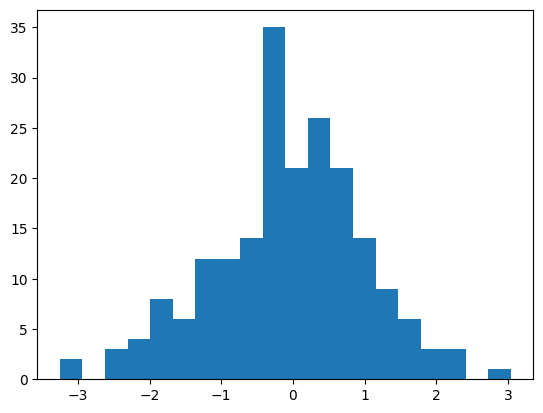

In [28]:
import matplotlib.pyplot as plt

plt.hist(X[:,2], bins=20)
plt.show()

И распределение целевого признака:

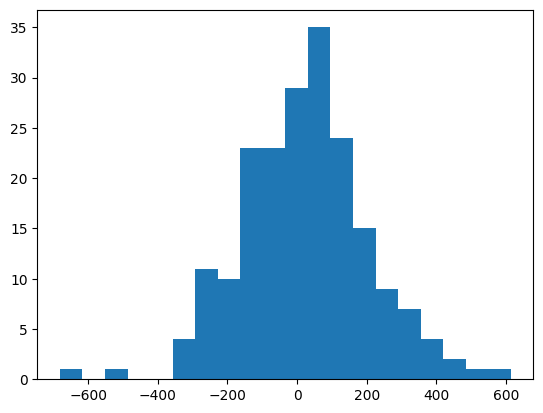

In [29]:
plt.hist(y, bins=20)
plt.show()

Проверим, нет ли у нас константных признаков, оценим минимальную и максимальную дисперсию:

In [25]:
import numpy as np

np.apply_along_axis(np.var, 0, X).min(), np.apply_along_axis(np.var, 0, X).max()

(np.float64(0.7786937224398176), np.float64(1.2889466789254826))

Разобъем выборку на обучающую и тестовую:

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42
)

В качестве метрики качества будем использовать [коэффицент детерминации](https://ru.wikipedia.org/wiki/%D0%9A%D0%BE%D1%8D%D1%84%D1%84%D0%B8%D1%86%D0%B8%D0%B5%D0%BD%D1%82_%D0%B4%D0%B5%D1%82%D0%B5%D1%80%D0%BC%D0%B8%D0%BD%D0%B0%D1%86%D0%B8%D0%B8) (R<sup>2</sup>) - доля дисперсии целевой переменной, объясняемая моделью.

Оценим, какая метрика достижима на обучаемой и тестовой выборке, если использовать порождающую модель:

In [54]:
from sklearn.metrics import r2_score

y_ideal_test = X_test@coef + bias
y_ideal_train = X_train@coef + bias

r2_score(y_test, y_ideal_test), r2_score(y_train, y_ideal_train)

(0.9859461349644831, 0.9872027728575306)

100% точность недостижима, т.к. в целевой переменной присутствует шумовая составляющая.

Обучим модель с идеально отобранными признаками:

In [55]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(X_train[:,:n_informative], y_train)
p_test = reg.predict(X_test[:,:n_informative])
p_train = reg.predict(X_train[:,:n_informative])
r2_score(y_test, p_test), r2_score(y_train, p_train)

(0.9837715073179032, 0.9882251848734053)

Обучим линейную модель без отбора признаков:

In [56]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(X_train, y_train)
p_test = reg.predict(X_test)
p_train = reg.predict(X_train)
r2_score(y_test, p_test), r2_score(y_train, p_train)

(-41.862781118639205, 1.0)

Здесь сильно проявляет себя переобучение.

Посмотрим на распределение признаков и целевого признака:

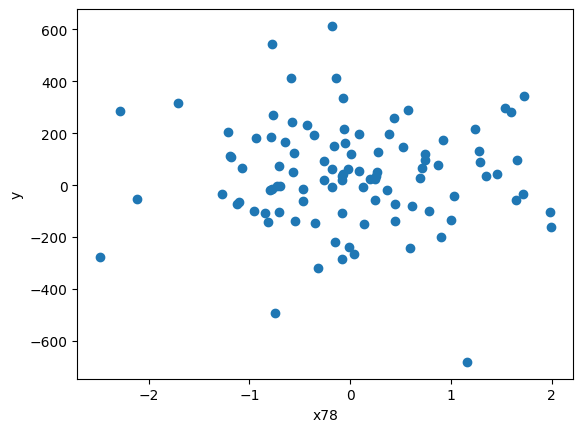

In [57]:
feature_index = 78
plt.plot(X_train[:,feature_index], y_train, 'o')
plt.xlabel(f'x{feature_index}')
plt.ylabel('y')
plt.show()

In [58]:
import numpy as np


sorted_corr = sorted([(i, np.corrcoef(y_train, X_train[:,i])[0,1]) for i in range(n_features)], key=lambda x: -abs(x[1]))
sorted_corr[:30]

[(5, np.float64(0.5095543857675916)),
 (4, np.float64(0.5024618741114489)),
 (9, np.float64(0.44998591098971197)),
 (7, np.float64(0.4367093869656259)),
 (0, np.float64(0.34713190071682687)),
 (6, np.float64(0.3463342716428371)),
 (1, np.float64(0.33089945231712736)),
 (13, np.float64(-0.239179736494678)),
 (27, np.float64(0.23744088946073286)),
 (77, np.float64(-0.2086146460397395)),
 (15, np.float64(0.19523391614666244)),
 (81, np.float64(0.18616873751946428)),
 (70, np.float64(0.18532113373003797)),
 (24, np.float64(-0.18332587845302478)),
 (84, np.float64(0.17764790166658898)),
 (63, np.float64(0.1559869813182948)),
 (34, np.float64(0.1527113855337564)),
 (98, np.float64(-0.15243529132558295)),
 (3, np.float64(0.1490777556161509)),
 (42, np.float64(-0.14852518625882888)),
 (25, np.float64(0.14818000832315154)),
 (59, np.float64(-0.14472309706831424)),
 (16, np.float64(-0.14380564104930446)),
 (54, np.float64(0.1355934766531379)),
 (67, np.float64(0.13180958586188954)),
 (94, np.flo

Будем включать признаки один за одним в порядке убывания модуля коэффициента корреляции и оценим R<sup>2</sup> на тестовой и обучающей выборке:

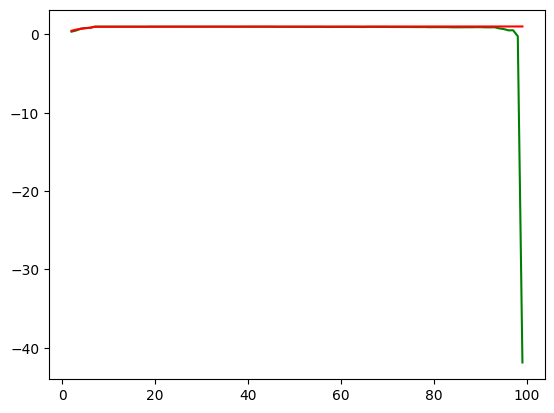

(22, 0.9706540965104585)

In [59]:
r2_test = []
r2_train = []
num_features = []
for i in range(2, n_features+1):
  selected = list(map(lambda x: x[0], sorted_corr[:i]))
  reg = LinearRegression()
  reg.fit(X_train[:,selected], y_train)
  p_test = reg.predict(X_test[:,selected])
  p_train = reg.predict(X_train[:,selected])
  num_features.append(i)
  r2_test.append(r2_score(y_test, p_test))
  r2_train.append(r2_score(y_train, p_train))

plt.plot(num_features, r2_test, 'g')
plt.plot(num_features, r2_train, 'r')
plt.show()
max(zip(num_features, r2_test), key=lambda x: x[1])

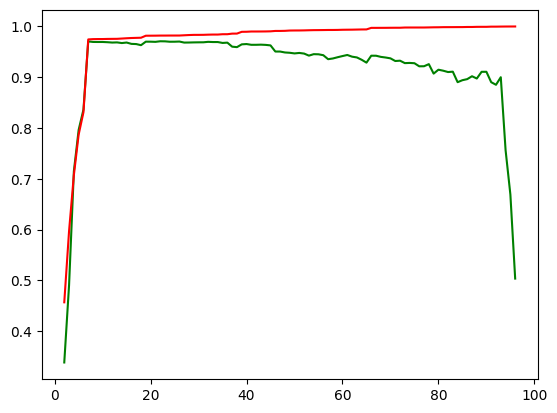

In [37]:
top = 95
plt.plot(num_features[:top], r2_test[:top], 'g')
plt.plot(num_features[:top], r2_train[:top], 'r')
plt.show()

In [60]:
sorted_corr[:22]

[(5, np.float64(0.5095543857675916)),
 (4, np.float64(0.5024618741114489)),
 (9, np.float64(0.44998591098971197)),
 (7, np.float64(0.4367093869656259)),
 (0, np.float64(0.34713190071682687)),
 (6, np.float64(0.3463342716428371)),
 (1, np.float64(0.33089945231712736)),
 (13, np.float64(-0.239179736494678)),
 (27, np.float64(0.23744088946073286)),
 (77, np.float64(-0.2086146460397395)),
 (15, np.float64(0.19523391614666244)),
 (81, np.float64(0.18616873751946428)),
 (70, np.float64(0.18532113373003797)),
 (24, np.float64(-0.18332587845302478)),
 (84, np.float64(0.17764790166658898)),
 (63, np.float64(0.1559869813182948)),
 (34, np.float64(0.1527113855337564)),
 (98, np.float64(-0.15243529132558295)),
 (3, np.float64(0.1490777556161509)),
 (42, np.float64(-0.14852518625882888)),
 (25, np.float64(0.14818000832315154)),
 (59, np.float64(-0.14472309706831424))]

Такая процедура не позволила найти все информативные признаки и в наборе отобранных признаков присутствует немало посторонних признаков.

В [sklearn.feature_selection](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.feature_selection) есть готовые инструменты для univariate feature selection и функции оценки признаков.

Посмотрим как работает `SelectKBest` и `r_regression`:

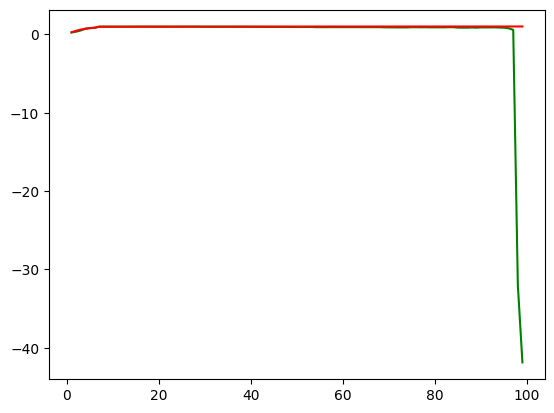

(15, 0.9752763154195188)

In [39]:
from sklearn.feature_selection import SelectKBest, r_regression, f_regression, mutual_info_regression

kb_test = []
kb_train = []
kb_k = []
for k in range(1, n_features+1):
  selector = SelectKBest(r_regression, k=k)
  X_train_sel = selector.fit_transform(X_train, y_train)
  reg = LinearRegression()
  reg.fit(X_train_sel, y_train)
  X_test_sel = selector.transform(X_test)
  p_test = reg.predict(X_test_sel)
  p_train = reg.predict(X_train_sel)
  kb_k.append(k)
  kb_test.append(r2_score(y_test, p_test))
  kb_train.append(r2_score(y_train, p_train))

plt.plot(kb_k, kb_test, 'g')
plt.plot(kb_k, kb_train, 'r')
plt.show()
max(zip(kb_k, kb_test), key=lambda x: x[1])

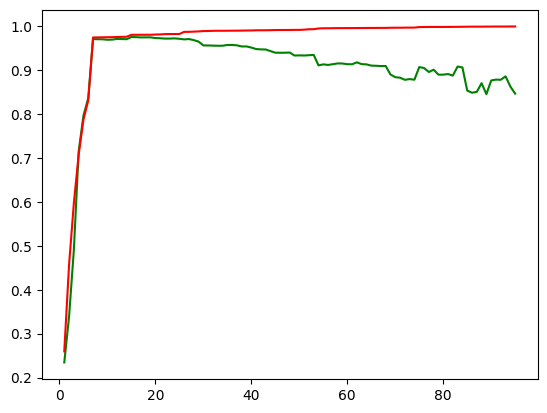

In [40]:
top = 95
plt.plot(kb_k[:top], kb_test[:top], 'g')
plt.plot(kb_k[:top], kb_train[:top], 'r')
plt.show()

Хороший вариант решения нашей синтетической задачи - использование L1-регуляризации:

In [61]:
from sklearn.linear_model import Lasso

reg = Lasso(alpha=3.0)

reg.fit(X_train, y_train)
p_test = reg.predict(X_test)
p_train = reg.predict(X_train)
r2_score(y_test, p_test), r2_score(y_train, p_train)

(0.9831598618623875, 0.9888821382500844)

Посмотрим на коэффициенты этой модели:

In [62]:
reg.coef_

array([ 5.42299075e+01,  6.44043540e+01,  9.26953071e+00,  1.00657811e+01,
        4.46388725e+01,  9.31199561e+01,  3.73103798e+01,  8.13190909e+01,
        1.17485822e+01,  5.96955636e+01, -0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -1.78384036e+00,  8.01491264e-01,  3.48121537e-02,
       -0.00000000e+00,  2.50698381e+00,  0.00000000e+00, -3.73348466e-01,
        1.61718670e-02, -3.98138509e-01,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00,  1.18585176e+00,  0.00000000e+00,
       -0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00, -1.48389329e+00, -0.00000000e+00, -0.00000000e+00,
       -2.43289022e-01, -0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  9.00556742e-01,
        0.00000000e+00, -

Отличное решение для нашей задачи дает совместное использование Lasso и RFECV (Recursive Feature Elimination with Cross-Validation to select features):

In [66]:
from sklearn.feature_selection import RFECV

estimator = Lasso()
selector = RFECV(estimator, step=2, cv=3)
selector = selector.fit(X_train, y_train)
selector.support_

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False, False, False, False, False, False, False,  True,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False])

In [67]:
selector.ranking_

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1, 20, 45, 45,  4, 16, 19, 14,
        1, 38, 13,  6,  2, 43, 39, 19, 42, 44,  4, 44, 43, 15, 42, 14, 41,
        9,  6, 41, 18, 40, 20, 40,  3, 11, 39, 23, 38, 37, 21, 16, 25, 25,
        3, 27, 27, 26,  7, 26, 34, 10, 33, 33, 32, 32,  8, 24,  7, 37, 36,
       17,  8, 18, 36, 35,  5,  9, 35, 21, 31, 31, 24, 10, 30, 23, 34, 13,
        2, 22,  5, 29, 15, 12, 17, 30, 29, 22, 12, 28, 28, 11])

Видно, что отобраны только 10 первых признаков! Но нам немного повезло, при других значениях step алгоритм начинает отбирать посторонние признаки.

Оценим качество этой модели на тестовой выборке:

In [68]:
r2_score(y_test, selector.predict(X_test))

0.9835259990192102

Что мы увидели на примере этой задачи?

1. Если не проводить отбор признаков, то можем столкнуться с переобучением.

1. Отбор признаков можно проводить ДО ОБУЧЕНИЯ модели. Это методы фильтрации признаков. Они не избавляют нас от выбора количества признаков, которые мы должны отобрать.

1. Отбор признаков можно проводить с помощью процедур анализа весов признаков, которые формируются моделью В ХОДЕ ОБУЧЕНИЯ.

1. Также можно удалять до обучения модели признаки с малой дисперсией. Мы это не делали, т.к. таких признаков у нас не было.

1. Мы не затронули тему дубликатов признаков или исключения похожих признаков.

1. Еще одной причиной для отбора признаков может быть сокращение вычислительных затрат, например, это актуально для real time моделей с высоким RPS и малым временем отклика. В этом случае ищут оптимальный баланс между точностью модели и скоростью вычислений.

В общем случае задача выбора признаков является вычислительно трудной, и не всегда простые эвристики срабатывают. Зависимости между признаками и целевой переменной могут быть гораздо сложнее, чем линейная. Можете самостоятельно сформировать синтетические наборы данных с помощью функций [make_friedman1](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_friedman1.html), [make_friedman2](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_friedman2.html), [make_friedman3](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_friedman3.html) и посмотреть как работают различные методы отбора.

Есть также методы отбора признаков на основе различных эвристик - имитация отжига, генетические алгоритмы и др.

Также для отбора признаков можно использовать инструменты, которые используются для подбора гиперпараметров, например, Hyperopt: https://celmore25.medium.com/automated-feature-selection-with-hyperopt-46865e1b4fce


## Вернемся к реальным задачам

Какие особенности работы с признаками в реальных задачах в отличие от синтетики?

1. В задачах, решаемых с помощью классического ML, большую часть признаков мы не получаем в готовом виде, а сами выбираем алгоритм их вычисления из исходных данных. Осмысленный подход к разработке признаков (понимание предметной области) как правило дает хорошие результаты, но не все гипотезы подтверждаются на практике.

2. Признаки часто имеют какие-то параметры, мы можем сформировать различные вариации одного признака с разными значениями параметра.

3. В реальных наборах данных не встречаются строгие математические зависимости целевого признака от произведения двух признаков, "шахматные доски", синунсоиды и т.п. Но подобные функции иногда применяются на практике для конструирования признаков, например, sin и cos могут использоваться для кодирования времени суток, чтобы не было резкого скачка признака в полночь.

4. Важна не только информативность признака, но и его стабильность во времени.

5. На вычисление большого количества признаков на значительном по объему наборе исходных данных может уйти много времени. Поэтому вычисляем каждый признак на некоторой выборке, оцениваем информативность признака, его сходство с ранее отобранными, стабильность, если все хорошо, то вычисляем его на всей выборке.

6. Методы фильтрации признаков играют существенную роль. Большая часть признаков отбрасывается до обучениям модели.

7. Сложный эвристический отбор признаков практически не используется, т.к. из-за дрейфов в данных этот "оптимальный" набор может очень быстро стать неоптимальным, а замена модели в проде иногда довольно дорогостоящее мероприятие.

8. Процесс работы с признаками автоматизирован - end-to-end ML pipelines.

9. Для хранения признаков используется feature store.


## Feature store

Множество реализаций открытых и проприетарных.

Мы используем свою разработку:
- колоночное хранение значений признаков в сжатом виде - можно записать новый признак, прочитать, удалить;
- партиционирование;
- встроенный контроль целостности и качества данных - все признаки в задаче должны храниться в одном и том же порядке (совпадать по id примеров), все партиции одного признака должны быть вычислены с помощью одного и того же шаблона;
- сборка матрицы признаков из заданного набора признаков;
- сэмплирование.

Feature store - это в т.ч.:
- хранение данных, которые не помещаются в RAM;
- возобновление расчетов признаков после сбоев или возможность вычислить признаки на новой порции данных;
- унифицированный интерфейс для разных проектов.

## Concept drift

Причины низкого качества прогнозов:
- Переобучение
- Недообучение
- Дрейф концепций (concept drift)

В последнем случае меняется распределение входных признаков модели, распределение целевого признака, совместное распределение признаков и целевого признака.

Для детекции дрейфа можно использовать различные подходы и инструменты. Рекомендую вам самостоятельно посмотреть библиотеку [Evidently](https://docs.evidentlyai.com/). Мы рассмотрим как можно использовать pseudo labeling.


## Pseudo labeling

Основная идея псевдолейблинга - в качестве целевой метки для каждого примера данных указываем из какой выборки взят этот пример. Если на такой разметке обучить классификатор и применить его к новой порции данных, мы сможем увидеть на какую исходную выборку она больше похожа. Как правило, чем больше отличаются исходные выборки, тем лучшее качество классификатора можно получить.

Pseudo labeling нередко используется в соревновательном ML. Но его можно использовать и для оценки дрейфа, если мы сравниваем выборки, сформированные за разные периоды времени.

Проверим как это работает на синтетической задаче. Сформируем две выборки из нормально распределенных случайных величин:

In [69]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

np.random.seed(43)
X1 = np.random.normal(0, 1, (1000, 20))
X2 = np.random.normal(0, 1, (1000, 20))

X1_train, X1_test = train_test_split(X1, test_size=0.5, random_state=42)
X2_train, X2_test = train_test_split(X2, test_size=0.5, random_state=42)

X_train = np.concatenate((X1_train, X2_train))
y_train = np.concatenate((np.zeros(len(X1_train)), np.ones(len(X2_train))))
X_test = np.concatenate((X1_test, X2_test))
y_test = np.concatenate((np.zeros(len(X1_test)), np.ones(len(X2_test))))

cl = XGBClassifier()
cl.fit(X_train, y_train)
p_test = cl.predict_proba(X_test)[:,1]
roc_auc_score(y_test, p_test)

np.float64(0.507252)

ROC AUC близкий к 0.5 указывает на отсутствие различий выборок.

А теперь повторим этот эксперимент со смещением в одном из признаков:

In [70]:
np.random.seed(42)
X1 = np.random.normal(0, 1, (1000, 20))
X2 = np.random.normal(0, 1, (1000, 20))
X2[:,17] = X2[:,17] + 1.0  # добавляем смещение

X1_train, X1_test = train_test_split(X1, test_size=0.5, random_state=42)
X2_train, X2_test = train_test_split(X2, test_size=0.5, random_state=42)

X_train = np.concatenate((X1_train, X2_train))
y_train = np.concatenate((np.zeros(len(X1_train)), np.ones(len(X2_train))))
X_test = np.concatenate((X1_test, X2_test))
y_test = np.concatenate((np.zeros(len(X1_test)), np.ones(len(X2_test))))

cl = XGBClassifier()
cl.fit(X_train, y_train)
p_test = cl.predict_proba(X_test)[:,1]
roc_auc_score(y_test, p_test)

np.float64(0.709632)

С помощью важности признаков мы можем определить, в каких именно признаках проявляется различие выборок:

In [48]:
sorted(zip(range(20),cl.feature_importances_), key=lambda x: -x[1])

[(17, np.float32(0.18359295)),
 (5, np.float32(0.056193788)),
 (0, np.float32(0.053665303)),
 (11, np.float32(0.05073011)),
 (3, np.float32(0.049030673)),
 (14, np.float32(0.048897814)),
 (1, np.float32(0.046170477)),
 (13, np.float32(0.044206496)),
 (2, np.float32(0.04419659)),
 (19, np.float32(0.04305917)),
 (8, np.float32(0.042651415)),
 (16, np.float32(0.041104864)),
 (6, np.float32(0.040817555)),
 (12, np.float32(0.03957045)),
 (4, np.float32(0.037883345)),
 (10, np.float32(0.037726916)),
 (9, np.float32(0.03751717)),
 (7, np.float32(0.035005778)),
 (18, np.float32(0.03498396)),
 (15, np.float32(0.032995243))]

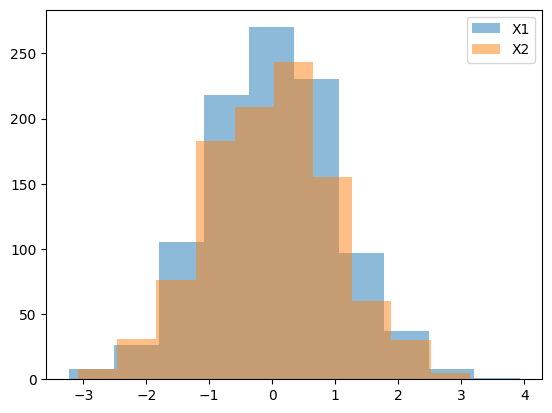

In [49]:
plt.hist(X1[:,15], alpha=0.5, label='X1')
plt.hist(X2[:,15], alpha=0.5, label='X2')
plt.legend(loc='upper right')
plt.show()

На практике дрейфы наблюдаются практически всегда, наша цель - по возможности снизить их влияние, выбрать такие признаки, чтобы модель деградировала не так быстро.

## Сколько признаков использовать?

Правило 20 EPV (events per variable) - на каждый признак должно быть не менее 20 примеров минорного класса ([Frank E. Harrell, Regression Modeling Strategies](https://link.springer.com/book/10.1007/978-1-4757-3462-1)).

Например, в выборке 10 тысяч примеров, 1 тыс. из них - положительные, 9 тыс. - отрицательные. Для такой выборки не стоит использовать более 1000/20 = 50 признаков.

## PSI



 PSI (Population Stability Index) — это метрика, которая показывает, насколько сильно изменилось распределение данных со временем или между двумя выборками.


**Как интерпретировать значения PSI:**

1) PSI < 0.1: Изменений практически нет. Данные стабильны, модель можно использовать.

2) 0.1 ≤ PSI < 0.25: Небольшие изменения. Стоит присмотреться к признаку или запланировать переобучение.

3) PSI ≥ 0.25: Значительный сдвиг. Признак стал «другим», использовать старую модель опасно.


$$PSI = \sum_{i=1}^{n} \left( (\% \text{Actual}_i - \% \text{Expected}_i) \cdot \ln\left( \frac{\% \text{Actual}_i}{\% \text{Expected}_i} \right) \right)$$


Часто PSI используют как фильтр перед обучением:

1) Вы считаете PSI для признаков между обучающей и тестовой выборкой.
2) Если у признака высокий PSI, вы удаляете его (даже если он очень важен по мнению RFECV), потому что он нестабилен и приведет к ошибкам в будущем.


**Permutation Feature Importance** (важность признаков на основе перестановок) — это алгоритм, который измеряет значимость признака, оценивая, насколько падает качество предсказания модели, если значения этого признака «испортить».


Как это работает (алгоритм):
1) Базовый замер: Обучается модель и замеряется её метрика качества (например, Accuracy или
) на проверочном наборе данных.

2) Перемешивание (Shuffle): Берется один конкретный признак (столбец), и его значения внутри этого столбца перемешиваются случайным образом между строками.


Суть: Все остальные признаки остаются на месте, но связь «испорченного» признака с целевой переменной разрывается.

3) Повторный замер: Модель делает предсказания на этих «испорченных» данных, и метрика качества замеряется снова.
Расчет важности: Разница между базовой метрикой и новой и есть важность признака. Чем сильнее упало качество, тем важнее был признак.


Почему это лучше стандартных методов (типа feature_importances_ в деревьях):


1)  Стандартная важность в Random Forest часто завышает значимость признаков с огромным количеством уникальных значений (например, ID или даты). Permutation Importance лишен этой ошибки.


2) Модельная независимость: Метод работает с любым алгоритмом (линейная регрессия, SVM, нейросети, градиентный бустинг), так как он смотрит только на входные данные и результат, а не «внутрь» модели.


Реальная польза: Его можно считать на отложенной (test) выборке. Это показывает, какие признаки модель реально использует для обобщения, а не какие она просто «зазубрила» при обучении.


In [50]:
from sklearn.datasets import make_classification
import pandas as pd

# 1. Генерируем данные (возвращает numpy arrays)
X_array, y_array = make_classification(
    n_samples=1000,      # количество строк
    n_features=20,       # всего признаков
    n_informative=15,    # из них реально влияют на таргет
    n_redundant=5,       # из них "лишние" (линейные комбинации информативных)
    n_classes=2,         # количество классов (бинарная классификация)
    flip_y=0.01,         # 1% шума (случайное перемешивание таргета)
    random_state=42      # для воспроизводимости
)

X = pd.DataFrame(X_array, columns=[f'feature_{i}' for i in range(20)])

print(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_array, test_size=0.5, random_state=42
)

Index(['feature_0', 'feature_1', 'feature_2', 'feature_3', 'feature_4',
       'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9',
       'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14',
       'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19'],
      dtype='object')


In [51]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 1. Обучаем модель (например, случайный лес)
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 2. Считаем Permutation Importance
# n_repeats — сколько раз перемешивать каждый признак (для стабильности)
result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)

# 3. Выводим важность признаков
for i in result.importances_mean.argsort()[::-1]:
    print(f"{X.columns[i]}: {result.importances_mean[i]:.3f} +/- {result.importances_std[i]:.3f}")


feature_12: 0.090 +/- 0.012
feature_2: 0.045 +/- 0.008
feature_4: 0.026 +/- 0.010
feature_5: 0.025 +/- 0.007
feature_6: 0.020 +/- 0.011
feature_10: 0.010 +/- 0.008
feature_16: 0.009 +/- 0.005
feature_14: 0.008 +/- 0.002
feature_8: 0.007 +/- 0.004
feature_7: 0.007 +/- 0.004
feature_9: 0.006 +/- 0.006
feature_11: 0.005 +/- 0.005
feature_3: 0.004 +/- 0.004
feature_13: 0.003 +/- 0.003
feature_15: 0.001 +/- 0.005
feature_1: 0.000 +/- 0.004
feature_19: -0.000 +/- 0.004
feature_0: -0.001 +/- 0.006
feature_18: -0.010 +/- 0.004
feature_17: -0.017 +/- 0.006
